In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive/t2/masks_2/

CNV  DRUSEN  NORMAL


In [6]:
import torch
from torchvision import models

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

num_classes = 3  # CNV, DRUSEN, NORMAL

model = models.resnet18(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)

ckpt = torch.load("/content/oct_modelvar2_2_resnet18.pth", map_location=device)

# dacă e salvat ca dict cu "state_dict"
if "state_dict" in ckpt:
    state_dict = ckpt["state_dict"]
else:
    state_dict = ckpt

# scoate prefix "module." dacă a fost antrenat pe DataParallel
new_state = {}
for k,v in state_dict.items():
    nk = k.replace("module.", "")
    new_state[nk] = v

model.load_state_dict(new_state, strict=False)
model.to(device)
model.eval()
print("Model loaded OK")


Using: cpu
Model loaded OK


In [5]:
import os

root_dir = "/content/drive/MyDrive/t2/masks_2/DRUSEN"

# extensii suportate
extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

total_images = 0
for root, dirs, files in os.walk(root_dir):
    count = sum(1 for f in files if f.lower().endswith(extensions))
    if count > 0:
        print(f"{root}: {count} imagini")
        total_images += count

print(f"\nTotal imagini în {root_dir} și toate subfolderele: {total_images}")


/content/drive/MyDrive/t2/masks_2/DRUSEN/1: 5 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/10: 15 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/11: 2 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/12: 7 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/13/OD: 10 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/13/OS: 15 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/14/OD: 26 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/14/OS: 25 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/15: 6 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/16: 6 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/17: 22 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/18/OD: 5 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/18/OS: 1 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/19: 10 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/2: 14 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/20: 31 imagini
/content/drive/MyDrive/t2/masks_2/DRUSEN/21: 14 imagini
/content/drive/MyDrive/t2/masks_2/DRUSE

In [7]:
import os
import torch
from pathlib import Path
from PIL import Image
import torchvision.transforms as T
from tqdm import tqdm  # pentru progress bar

# === Device ===
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Eval on:", device)

# === Root dataset ===
root_dir = "/content/drive/MyDrive/t2/masks_2/"

# === Clase și mapping ===
classes = ["CNV", "DRUSEN", "NORMAL"]
class_to_idx = {c:i for i,c in enumerate(classes)}

# === Transformări EXACT ca la antrenare ===
transform = T.Compose([
    T.Resize((160, 160)),  # dimensiunea folosită la antrenare
    T.ToTensor(),           # fără Normalize
])

# === Counters pentru evaluare ===
total = 0
correct = 0
per_class_correct = {c:0 for c in classes}
per_class_total = {c:0 for c in classes}

model.eval()  # modelul trebuie să fie deja încărcat și pe device

# === Începem evaluarea ===
with torch.no_grad():
    for cls in classes:
        class_folder = Path(root_dir) / cls

        # ia toate imaginile din toate subfolderele
        image_paths = []
        for ext in ("*.jpg","*.jpeg","*.png","*.bmp","*.tif","*.tiff"):
            image_paths.extend(class_folder.rglob(ext))

        print(f"\n[INFO] {cls}: găsite {len(image_paths)} imagini")

        # tqdm pentru live progress
        for path in tqdm(image_paths, desc=f"Evaluare {cls}", unit="img"):
            try:
                img = Image.open(path).convert("RGB")
            except:
                print(f"[WARNING] nu s-a putut deschide: {path}")
                continue

            img_t = transform(img).unsqueeze(0).to(device)
            out = model(img_t)
            pred = torch.argmax(out, dim=1).item()

            # actualizăm statistici
            total += 1
            per_class_total[cls] += 1
            if pred == class_to_idx[cls]:
                correct += 1
                per_class_correct[cls] += 1

            # LIVE update în tqdm
            tqdm.write(f"{cls}: {per_class_correct[cls]}/{per_class_total[cls]} | "
                       f"TOTAL: {correct}/{total}")

# === Evaluare finală ===
print("\n=== Evaluare finală ===")
print(f"Total accuracy: {correct}/{total} = {correct/total*100:.2f}%\n")
for cls in classes:
    if per_class_total[cls] > 0:
        acc = per_class_correct[cls] / per_class_total[cls] * 100
        wrong = per_class_total[cls] - per_class_correct[cls]
        print(f"{cls}: {per_class_correct[cls]}/{per_class_total[cls]} ({acc:.2f}%) | gresite: {wrong}")


Eval on: cpu

[INFO] CNV: găsite 1152 imagini


Evaluare CNV:   0%|          | 1/1152 [00:00<17:01,  1.13img/s]

CNV: 0/1 | TOTAL: 0/1


Evaluare CNV:   0%|          | 2/1152 [00:01<13:03,  1.47img/s]

CNV: 1/2 | TOTAL: 1/2


...

NORMAL: 1197/1374 | TOTAL: 2353/3568


Evaluare NORMAL: 100%|█████████▉| 1375/1376 [13:34<00:00,  1.84img/s]

NORMAL: 1198/1375 | TOTAL: 2354/3569


Evaluare NORMAL: 100%|██████████| 1376/1376 [13:35<00:00,  1.69img/s]

NORMAL: 1199/1376 | TOTAL: 2355/3570

=== Evaluare finală ===
Total accuracy: 2355/3570 = 65.97%

CNV: 796/1152 (69.10%) | gresite: 356
DRUSEN: 360/1042 (34.55%) | gresite: 682
NORMAL: 1199/1376 (87.14%) | gresite: 177


Eval on: cpu

[INFO] CNV: 1152 imagini


Evaluare CNV:   0%|          | 1/1152 [00:00<08:08,  2.36img/s]

CNV: 0/1 | TOTAL: 0/1


Evaluare CNV:   0%|          | 2/1152 [00:00<06:10,  3.10img/s]

CNV: 1/2 | TOTAL: 1/2


...

Evaluare NORMAL: 100%|█████████▉| 1375/1376 [02:24<00:00,  9.13img/s]

NORMAL: 1197/1374 | TOTAL: 2353/3568
NORMAL: 1198/1375 | TOTAL: 2354/3569


Evaluare NORMAL: 100%|██████████| 1376/1376 [02:24<00:00,  9.50img/s]


NORMAL: 1199/1376 | TOTAL: 2355/3570

=== Evaluare finala ===
Total accuracy: 2355/3570 = 65.97%

CNV: 796/1152 (69.10%) | gresite: 356
DRUSEN: 360/1042 (34.55%) | gresite: 682
NORMAL: 1199/1376 (87.14%) | gresite: 177

Matricea de confuzie (bruta):
[[ 796  196  160]
 [  48  360  634]
 [  28  149 1199]]


<Figure size 600x600 with 0 Axes>

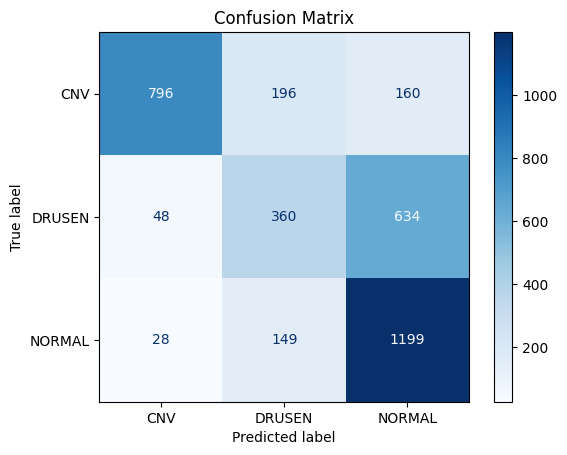

<Figure size 600x600 with 0 Axes>

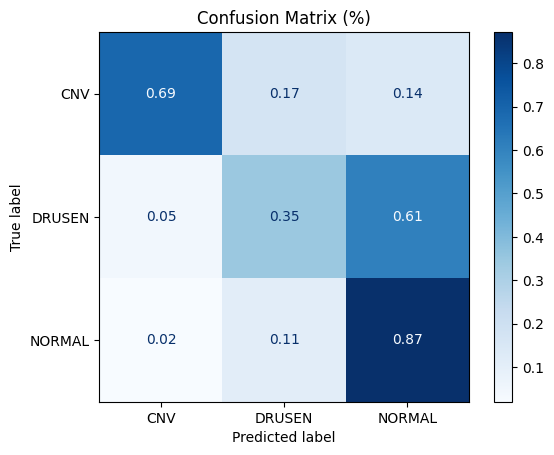

In [8]:
import os
import torch
from pathlib import Path
from PIL import Image
import torchvision.transforms as T
from tqdm import tqdm

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ================= DEVICE =================
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Eval on:", device)

# ================= ROOT DATASET =================
root_dir = "/content/drive/MyDrive/t2/masks_2/"

# ================= CLASE =================
classes = ["CNV", "DRUSEN", "NORMAL"]
class_to_idx = {c: i for i, c in enumerate(classes)}

# ================= TRANSFORMARI (IDENTICE CU TRAIN) =================
transform = T.Compose([
    T.Resize((160, 160)),
    T.ToTensor(),   # fara Normalize
])

# ================= COUNTERS =================
total = 0
correct = 0
per_class_correct = {c: 0 for c in classes}
per_class_total = {c: 0 for c in classes}

# ================= CONFUSION MATRIX DATA =================
y_true = []
y_pred = []

# ================= MODEL =================
model = model.to(device)   # modelul trebuie sa fie deja incarcat
model.eval()

# ================= EVALUARE =================
with torch.no_grad():
    for cls in classes:
        class_folder = Path(root_dir) / cls

        # toate imaginile din subfoldere
        image_paths = []
        for ext in ("*.jpg", "*.jpeg", "*.png", "*.bmp", "*.tif", "*.tiff"):
            image_paths.extend(class_folder.rglob(ext))

        print(f"\n[INFO] {cls}: {len(image_paths)} imagini")

        for path in tqdm(image_paths, desc=f"Evaluare {cls}", unit="img"):
            try:
                img = Image.open(path).convert("RGB")
            except:
                print(f"[WARNING] nu s-a putut deschide: {path}")
                continue

            img_t = transform(img).unsqueeze(0).to(device)
            out = model(img_t)
            pred = torch.argmax(out, dim=1).item()

            true_label = class_to_idx[cls]

            # statistici
            total += 1
            per_class_total[cls] += 1
            if pred == true_label:
                correct += 1
                per_class_correct[cls] += 1

            # pentru confusion matrix
            y_true.append(true_label)
            y_pred.append(pred)

            tqdm.write(
                f"{cls}: {per_class_correct[cls]}/{per_class_total[cls]} | "
                f"TOTAL: {correct}/{total}"
            )

# ================= REZULTATE =================
print("\n=== Evaluare finala ===")
print(f"Total accuracy: {correct}/{total} = {correct/total*100:.2f}%\n")

for cls in classes:
    if per_class_total[cls] > 0:
        acc = per_class_correct[cls] / per_class_total[cls] * 100
        wrong = per_class_total[cls] - per_class_correct[cls]
        print(f"{cls}: {per_class_correct[cls]}/{per_class_total[cls]} "
              f"({acc:.2f}%) | gresite: {wrong}")

# ================= CONFUSION MATRIX =================
cm = confusion_matrix(y_true, y_pred)

print("\nMatricea de confuzie (bruta):")
print(cm)

# ================= AFISARE =================
plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

# ================= NORMALIZATA (%) =================
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_norm,
    display_labels=classes
)
disp.plot(cmap="Blues", values_format=".2f")
plt.title("Confusion Matrix (%)")
plt.show()
